# **Revisão Geral: Aprendizado de Máquina e o Pacote `scikit-learn`**

## 1. Inteligência Artificial, Machine Learning e Deep Learning
Antes de avançarmos para novos algoritmos, vamos organizar três termos que aparecem o tempo todo na tecnologia e na engenharia, mas que não significam a mesma coisa:

* **Inteligência Artificial (IA):** É o grande guarda-chuva. Qualquer programa capaz de tomar uma decisão ou imitar o raciocínio humano é IA — desde um jogo de xadrez antigo cheio de regras fixas (`SE isso, ENTÃO aquilo`) até os robôs atuais.
* **Aprendizado de Máquina (*Machine Learning* - ML):** É uma área dentro da IA. Aqui acontece uma virada de chave: em vez de o engenheiro digitar as regras no código, nós entregamos uma **tabela com exemplos do passado** e o computador usa estatística para **descobrir as regras sozinho**. É exatamente o que estamos fazendo neste curso!
* **Aprendizado Profundo (*Deep Learning* - DL):** É uma evolução dentro do *Machine Learning* inspirada nos neurônios humanos (Redes Neurais Profundas). É usado quando os dados são gigantescos e complexos demais para tabelas simples, como carros autônomos enxergando a rua em tempo real ou sistemas de voz e texto (como o ChatGPT).

<div style="text-align: center; margin: 20px 0;">
    <img src="./img/ia_ml_dl.png" alt="Círculos concêntricos mostrando IA, Machine Learning e Deep Learning" style="width: 45%; max-width: 500px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        Hierarquia conceitual: <i>Deep Learning</i> está dentro do <i>Machine Learning</i>, que faz parte da Inteligência Artificial.
    </p>
</div>

### 1.1 A Grande Diferença na Prática
Na programação tradicional (que aprendemos em algoritmos básicos), nós damos os **Dados** e escrevemos as **Regras** para o computador devolver a **Resposta**.

No **Aprendizado Supervisionado** (*Supervised Learning*), nós invertemos o processo: entregamos os **Dados** junto com as **Respostas Certas** (o nosso gabarito), e o computador descobre as **Regras** (que chamamos de **Modelo**).

<div style="text-align: center; margin: 20px 0;">
    <img src="./img/tradicional_vs_ml.png" alt="Comparação entre Programação Tradicional e Machine Learning" style="width: 55%; max-width: 600px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        Mudança de paradigma: o algoritmo aprende as regras a partir dos exemplos históricos.
    </p>
</div>

> **💡 Por que isso é tão útil na Engenharia?**  
> Imagine tentar escrever na mão uma regra matemática para identificar um rosto com óculos analisando $4.096$ pixels, ou prever um AVC cruzando dezenas de exames clínicos! Com o *Machine Learning*, o algoritmo encontra esses padrões em segundos.

## 2. Dicionário Rápido do `scikit-learn`
Durante os códigos em Python, usamos várias palavras em inglês que são padrão no mundo inteiro. Veja na tabela abaixo a tradução direta do que cada uma significa nas nossas aulas:

<center>

| Termo em Inglês | Como aparece no código | O que significa na prática | Exemplo das nossas aulas |
|:---:|:---:|:---|:---|
| **Dataset** | `titanic3.csv`, `boston` | Conjunto de dados (a nossa tabela completa) | A lista com os 1.309 passageiros do Titanic |
| **Samples / Instances** | Linhas da matriz (`shape[0]`) | Amostras ou indivíduos analisados | Cada passageiro do navio ou cada casa avaliada |
| **Features** | Matriz **`X`** (Colunas) | Características ou atributos (as "pistas" de entrada) | Classe (`pclass`), Idade (`age`) e Sexo (`sex`) |
| **Target / Label** | Vetor **`y`** (Alvo) | O "gabarito" (a resposta que queremos prever) | Coluna `survived` (`0` = não, `1` = sim) |
| **Classifier** | Variável **`clf`** | O modelo matemático (nosso "aluno virtual") | `SVC()`, `GaussianNB()`, `DecisionTreeClassifier()` |
| **Hyperparameters** | `max_depth=3` | Botões de regulagem que definimos antes do treino | Limitar a árvore a 3 níveis de profundidade |
| **Overfitting** | Alta nota no treino e baixa no teste | **Sobreajuste ("Decoreba")**: o modelo decora o treino, mas erra em dados novos | Decorar o nome do passageiro em vez de aprender a regra geral |

</center>

## 3. Classificação vs. Regressão
Todos os algoritmos que estudamos até aqui buscam prever um resultado `y` a partir das características `X`. Porém, dependendo do tipo de resposta que queremos encontrar, dividimos os problemas em dois tipos:

1. **Problemas de Classificação (*Classification*):** Queremos escolher uma **categoria** dentro de uma lista fechada de opções (respostas discretas).
   * *Exemplos:* O e-mail é *Spam* ou *Ham*? O passageiro *Sobreviveu* (`1`) ou *Não Sobreviveu* (`0`)? O paciente *tem diabetes* ou *não tem*?
   * *Como avaliamos:* Medimos a **Acurácia** (*Accuracy*), que é a porcentagem de acertos exatos.

2. **Problemas de Regressão (*Regression*):** Queremos prever um **número contínuo** na reta real (um valor quantitativo).
   * *Exemplos:* Qual é o preço de venda de uma casa? Qual é a taxa exata de açúcar no sangue de um paciente? Qual a temperatura esperada para um motor elétrico em funcionamento?
   * *Como avaliamos:* Como é quase impossível acertar um valor contínuo com infinitas casas decimais, não usamos acurácia. Usamos o **Coeficiente de Determinação ($R^2$)**, que mede o quão perto as previsões chegaram perto dos valores reais (quanto mais próximo de $1.0$, mais perfeito é o modelo).

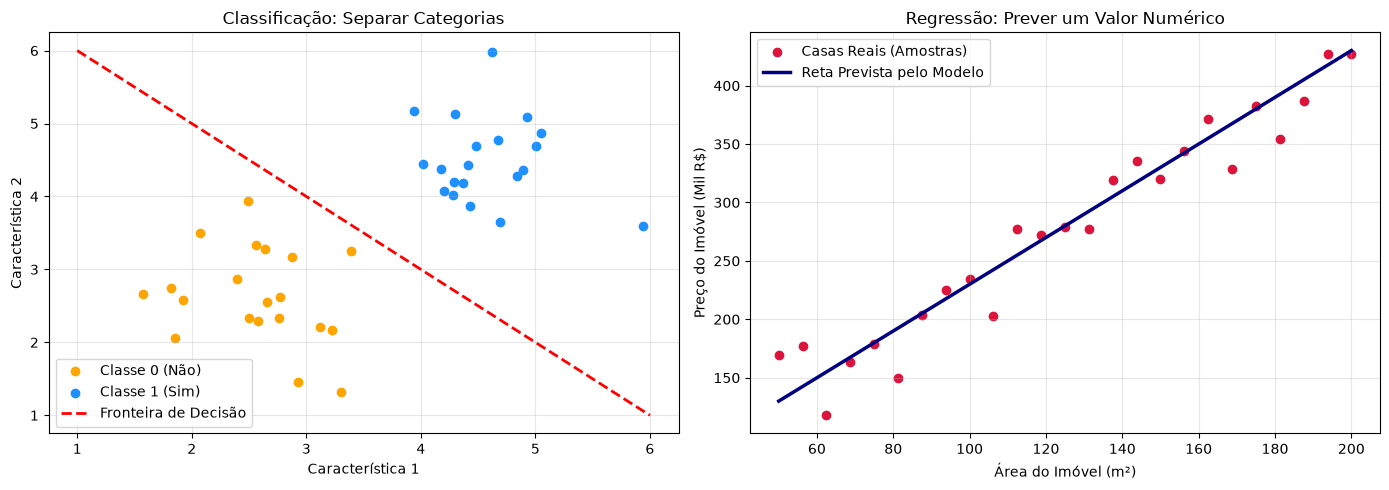

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(10)
plt.figure(figsize=(14, 5))

# Gráfico 1: Classificação (Separar grupos)
plt.subplot(1, 2, 1)
plt.scatter(np.random.normal(2.5, 0.6, 20), np.random.normal(2.5, 0.6, 20), color='orange', label='Classe 0 (Não)')
plt.scatter(np.random.normal(4.5, 0.6, 20), np.random.normal(4.5, 0.6, 20), color='dodgerblue', label='Classe 1 (Sim)')
plt.plot([1, 6], [6, 1], 'r--', linewidth=2, label='Fronteira de Decisão')
plt.title("Classificação: Separar Categorias")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.legend()
plt.grid(True, alpha=0.3)

# Gráfico 2: Regressão (Prever um valor contínuo)
plt.subplot(1, 2, 2)
x_reg = np.linspace(50, 200, 25)
y_reg = 2.0 * x_reg + 30 + np.random.normal(0, 20, 25)
plt.scatter(x_reg, y_reg, color='crimson', label='Casas Reais (Amostras)')
plt.plot(x_reg, 2.0 * x_reg + 30, color='navy', linewidth=2.5, label='Reta Prevista pelo Modelo')
plt.title("Regressão: Prever um Valor Numérico")
plt.xlabel("Área do Imóvel (m²)")
plt.ylabel("Preço do Imóvel (Mil R$)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Como Usar o `scikit-learn`: A Receita de 5 Passos
A grande vantagem do pacote **`scikit-learn`** (`sklearn`) é a sua padronização. Não importa o método que se está usando **SVM**, **Naïve Bayes** ou **Árvore de Decisão**, o passo a passo no código segue sempre a mesma estrutura!

1. **Pré-processamento (`sklearn.preprocessing`):** Limpamos os dados, preenchemos valores vazios e transformamos palavras em números (`LabelEncoder`, `OneHotEncoder`) ou colocamos as colunas na mesma escala numérica (`StandardScaler`).

2. **Divisão Treino e Teste (`train_test_split`):** Separamos o conjunto de dados em duas partes — geralmente **75% para treinamento** (`X_train`, `y_train`) para o modelo ser construído, e **25% para teste** (**`X_test`**, **`y_test`**) para avaliar se o modelo realmente aprendeu.

3. **Escolha do Modelo (Instanciação):** Criamos a variável `clf` escolhendo o algoritmo desejado (ex: **`clf = tree.DecisionTreeClassifier()`**).

4. **Treinamento (`.fit()`):** O comando **`clf.fit(X_train, y_train)`** faz o algoritmo cruzar os dados de treino com o gabarito e aprender as regras.

5. **Previsão e Avaliação (`.predict()` e `metrics`):** O comando **`y_pred = clf.predict(X_test)`** gera os palpites do modelo para os dados de teste. Em seguida, comparamos `y_pred` com o gabarito real `y_test`.

<div style="background-color: #cfcff8; border-left: 5px solid; border-right: 5px solid #773014; padding: 15px; margin: 15px -25px; border-radius: 4px; color: #5b0137;">
    <p style="color: #6d3651;">⚠️ <b>Regra Importante:</b> Por que nunca escolhemos o modelo olhando os dados de teste?</p>
    Os dados de teste (<code>X_test</code>) devem ficar "trancados no cofre" até o final do projeto! Se precisarmos testar várias configurações para escolher o melhor algoritmo antes da prova final, usamos a <b>Validação Cruzada</b> (<i>Cross-Validation</i>, como o <code><b>KFold</b></code> ou o <code><b>LeaveOneOut?</b></code>) apenas nos dados de treinamento.
</div>

## 5. Resumo dos Modelos

Veja como os modelos que já estudamos se conectam com o nosso próximo tema:

<center>

| Algoritmo | Como funciona a lógica | Ponto Forte | Limitação Principal |
|:---:|:---|:---|:---|
| **SVM (Máquina de Vetores de Suporte)** | Traça uma linha ou hiperplano para separar as classes com a maior margem possível | Excelente para dados com muitas colunas (ex: pixels de imagens) | Difícil de visualizar como a decisão foi tomada ("caixa-preta") |
| **Naïve Bayes** | Calcula a probabilidade de cada classe usando o Teorema de Bayes | Muito rápido e ótimo para textos e recomendações | Assume que as características são independentes entre si |
| **Árvore de Decisão (*Decision Tree*)** | Faz perguntas sequenciais (`<=`) dividindo os dados usando a Entropia | Fácil de interpretar visualmente (fluxograma claro) | Uma escolha ruim no topo da árvore não pode ser desfeita depois |
| **Floresta Randômica (*Random Forest*)** | Cria **várias árvores diferentes** sorteando dados e colunas, e faz uma votação entre elas | Corrige os erros de uma árvore isolada e evita o *overfitting* | Exige mais processamento do computador |  
</center>

## 6. Florestas Randômicas (*Random Forests*)
Por que precisamos criar uma "Floresta" de Árvores?
No tratamento dos dados do naufrágio do Titanic, vimos que a única **Árvore de Decisão** começou perguntando se o passageiro era homem ou mulher. Uma crítica comum a esse método é que, depois que a árvore divide os grupos no topo, ela não volta atrás. Se tivéssemos milhares de colunas na tabela, uma árvore sozinha poderia deixar passar padrões importantes.

A **Floresta Randômica** (*Random Forest*) resolve isso usando a ideia de um comitê (*Ensemble*): em vez de confiar em uma única árvore, o algoritmo sorteia partes dos dados e cria dezenas de árvores diferentes (`n_estimators=10`). No final, todas as árvores votam e a resposta da maioria vence!

<div style="text-align: center; margin: 20px 0;">
    <img src="./img/random_forest.png" alt="Esquema de uma Floresta Randômica" style="width: 50%; max-width: 550px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        Esquema de uma <b>Floresta Randômica</b>: várias árvores analisam subconjuntos dos dados e decidem juntas por votação.
    </p>
</div>

In [2]:
from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Carregando um conjunto de dados clássico do próprio scikit-learn (Classificação de Vinhos)
vinhos = datasets.load_wine()
X, y = vinhos.data, vinhos.target

# 2. Separando 75% para treinamento e 25% para teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=33)

# 3. Criando uma lista com os 4 classificadores estudados
modelos = [
    ("SVM (Linear)", SVC(kernel='linear', random_state=33)),
    ("Naïve Bayes", GaussianNB()),
    ("Árvore de Decisão", DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=33)),
    ("Floresta Randômica (10 árvores)", RandomForestClassifier(n_estimators=10, random_state=33))
]

print("Comparando a Acurácia dos modelos no mesmo conjunto de teste:\n")
for nome, clf in modelos:
    clf.fit(X_train, y_train)                       # 4. Treina o modelo
    y_pred = clf.predict(X_test)                    # 5. Faz a previsão no teste
    acc = metrics.accuracy_score(y_test, y_pred)    # Calcula a acurácia
    print(f"{nome:<32} | Acurácia: {acc:.3f} ({acc*100:.1f}%)")

Comparando a Acurácia dos modelos no mesmo conjunto de teste:

SVM (Linear)                     | Acurácia: 0.889 (88.9%)
Naïve Bayes                      | Acurácia: 1.000 (100.0%)
Árvore de Decisão                | Acurácia: 0.867 (86.7%)
Floresta Randômica (10 árvores)  | Acurácia: 0.956 (95.6%)
